# Formula 1 Data Analysis: Phase 5

## Power BI Data Model

This phase converts the outputs of Phases 2 and 3 into a star schema that Power BI can consume without further transformation.

| Layer | Tables |
| --- | --- |
| Dimensions | `dim_date`, `dim_race`, `dim_circuit`, `dim_driver`, `dim_constructor`, `dim_status` |
| Facts | `fact_results`, `fact_sprint_results`, `fact_race_performance`, `fact_pit_stops`, `fact_lap_times`, `fact_practice_sessions`, `fact_driver_standings`, `fact_constructor_standings` |

Outputs are written to `f1_powerbi/` as Parquet and CSV, together with a relationship list, a data dictionary and the Power BI guide.

Prerequisites: `f1_clean/` (Phase 2) and `f1_model/` (Phase 3).

## Setup

In [1]:
import os
import re
import shutil
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import FancyBboxPatch

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

try:
    from IPython.display import Markdown, display
except ImportError:
    display, Markdown = print, str

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

BASE = Path("/content") if IN_COLAB else Path(os.environ.get("F1_WORKDIR", "/tmp/f1"))
CLEAN_DIR, MODEL_DIR, PBI_DIR = (BASE / name for name in ("f1_clean", "f1_model", "f1_powerbi"))
PBI_DIR.mkdir(parents=True, exist_ok=True)

ERA_BINS = [1949, 1969, 1989, 2013, 2021, 2100]
ERA_LABELS = ["1950-69 Pioneer", "1970-89 Classic", "1990-2013 V10/V8", "2014-21 Hybrid", "2022+ Ground effect"]


def read_tables(folder, names):
    tables = {}
    for name in names:
        matches = list(folder.rglob(f"{name}.parquet")) or list(folder.rglob(f"{name}.csv"))
        if not matches:
            raise FileNotFoundError(f"{name} not found in {folder}. Run the previous phase first.")
        path = matches[0]
        tables[name] = pd.read_parquet(path) if path.suffix == ".parquet" else pd.read_csv(path)
    return tables


def to_snake(df):
    return df.rename(columns=lambda name: re.sub(r"(?<=[a-z0-9])([A-Z])", r"_\1", name).lower())

## 5.1 Load the source tables

In [2]:
clean = read_tables(CLEAN_DIR, [
    "circuits", "constructors", "drivers", "status", "races", "sprint_results", "qualifying",
    "lap_times", "pit_stops", "practice_sessions", "driver_standings", "constructor_standings",
])
model = read_tables(MODEL_DIR, ["fact_results", "fact_driver_race_perf"])
print({name: len(df) for name, df in {**clean, **model}.items()})

{'circuits': 78, 'constructors': 205, 'drivers': 835, 'status': 136, 'races': 1169, 'sprint_results': 612, 'qualifying': 11410, 'lap_times': 639293, 'pit_stops': 13029, 'practice_sessions': 2051, 'driver_standings': 35072, 'constructor_standings': 13701, 'fact_results': 26313, 'fact_driver_race_perf': 11938}


## 5.2 Dimension tables

Design decisions:

- `dim_race` is the central dimension. `dim_date` and `dim_circuit` hang off it as outriggers, so every fact table needs only one relationship to describe when and where an event happened.
- Data coverage flags (`has_qualifying_data`, `has_lap_data`, `has_pit_data`) let report authors filter out seasons where a measure is structurally empty.
- Column names use `snake_case`; key columns keep the same name in every table.

In [3]:
def date_key(dates):
    return (dates.dt.year * 10000 + dates.dt.month * 100 + dates.dt.day).astype("int32")


races = clean["races"]
calendar = pd.Series(pd.date_range(races["date"].min(), races["date"].max(), freq="D"))
dim_date = pd.DataFrame({
    "date_key": date_key(calendar),
    "date": calendar,
    "year": calendar.dt.year.astype("int16"),
    "quarter": calendar.dt.quarter.astype("int8"),
    "month": calendar.dt.month.astype("int8"),
    "month_name": calendar.dt.month_name(),
    "day": calendar.dt.day.astype("int8"),
    "day_of_week": (calendar.dt.dayofweek + 1).astype("int8"),
    "day_name": calendar.dt.day_name(),
    "is_weekend": calendar.dt.dayofweek >= 5,
})

performance_src = model["fact_driver_race_perf"]
race_laps = model["fact_results"].groupby("raceId")["race_laps"].first()

dim_race = pd.DataFrame({
    "race_id": races["raceId"],
    "race_label": races["year"].astype("string") + " " + races["race_name"],
    "race_name": races["race_name"],
    "year": races["year"],
    "round": races["round"],
    "rounds_in_season": races.groupby("year")["round"].transform("max").astype("int8"),
    "date_key": date_key(races["date"]),
    "date": races["date"],
    "circuit_id": races["circuitId"],
    "era": pd.cut(races["year"], ERA_BINS, labels=ERA_LABELS).astype("string"),
    "decade": races["decade"],
    "race_laps": races["raceId"].map(race_laps).astype("Int16"),
    "has_sprint": races["has_sprint"],
    "has_qualifying_data": races["raceId"].isin(clean["qualifying"]["raceId"]),
    "has_lap_data": races["raceId"].isin(performance_src.loc[performance_src["has_lap_data"], "raceId"]),
    "has_pit_data": races["raceId"].isin(performance_src.loc[performance_src["has_pit_data"], "raceId"]),
})

circuits = clean["circuits"]
dim_circuit = pd.DataFrame({
    "circuit_id": circuits["circuitId"], "circuit_ref": circuits["circuitRef"], "circuit_name": circuits["name"],
    "location": circuits["location"], "country": circuits["country_std"], "latitude": circuits["lat"],
    "longitude": circuits["lng"], "altitude_m": circuits["alt"],
})

drivers = clean["drivers"]
dim_driver = pd.DataFrame({
    "driver_id": drivers["driverId"], "driver_ref": drivers["driverRef"], "driver_name": drivers["driver_name"],
    "driver_code": drivers["code_filled"], "driver_number": drivers["number"], "birth_date": drivers["dob"],
    "nationality": drivers["nationality"],
})

constructors = clean["constructors"]
dim_constructor = pd.DataFrame({
    "constructor_id": constructors["constructorId"], "constructor_ref": constructors["constructorRef"],
    "constructor_name": constructors["constructor_name"], "nationality": constructors["nationality"],
})

dim_status = to_snake(clean["status"])[["status_id", "status", "status_group", "is_finished"]]

dimensions = {
    "dim_date": dim_date, "dim_race": dim_race, "dim_circuit": dim_circuit,
    "dim_driver": dim_driver, "dim_constructor": dim_constructor, "dim_status": dim_status,
}
display(pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1]} for name, df in dimensions.items()}).T)

,rows,columns
dim_date,27939,10
dim_race,1169,16
dim_circuit,78,8
dim_driver,835,7
dim_constructor,205,4
dim_status,136,4


## 5.3 Fact tables

Each fact table keeps only keys, measures and flags. Descriptive attributes live in the dimensions, which keeps the tables compact and prevents the relationship ambiguity described in the guide below.

In [4]:
RESULT_COLUMNS = [
    "result_id", "race_id", "driver_id", "constructor_id", "status_id",
    "grid_position", "starts_from_pit_lane", "qualifying_position", "best_q_ms", "reached_q3",
    "finish_position", "position_order", "points", "laps", "race_laps", "laps_completed_pct",
    "race_time_ms", "fastest_lap_ms", "fastest_lap_rank", "fastest_lap_speed",
    "positions_gained", "age_at_race",
    "is_classified", "is_finished", "is_dnf", "is_disqualified", "is_dns", "is_win", "is_podium",
    "is_points_finish", "has_fastest_lap", "started_on_pole", "is_shared_drive",
]
fact_results = to_snake(model["fact_results"]).rename(columns={
    "grid_clean": "grid_position", "grid_is_pitlane": "starts_from_pit_lane", "quali_position": "qualifying_position",
    "position": "finish_position", "milliseconds": "race_time_ms", "rank": "fastest_lap_rank",
    "is_finish": "is_finished", "is_dsq": "is_disqualified",
})[RESULT_COLUMNS]

sprint = to_snake(clean["sprint_results"]).merge(dim_status[["status_id", "status_group"]], on="status_id", how="left")
sprint = sprint.rename(columns={"grid_clean": "grid_position", "position": "finish_position"})
sprint["is_finished"] = sprint["status_group"].isin(["Finished", "Finished (Lapped)"])
sprint["is_win"] = sprint["finish_position"].eq(1).fillna(False).astype(bool)
sprint["is_podium"] = (sprint["finish_position"] <= 3).fillna(False).astype(bool)
has_real_grid = sprint["is_classified"] & sprint["grid_position"].notna()
sprint["positions_gained"] = (sprint["grid_position"].astype("float64") - sprint["position_order"]).where(has_real_grid).astype("Int16")
fact_sprint_results = sprint[[
    "result_id", "race_id", "driver_id", "constructor_id", "status_id", "grid_position", "finish_position",
    "position_order", "points", "laps", "fastest_lap_ms", "positions_gained", "is_classified",
    "is_finished", "is_win", "is_podium",
]]

fact_race_performance = to_snake(model["fact_driver_race_perf"]).rename(columns={
    "n_laps_recorded": "laps_recorded", "n_outlier_laps": "outlier_laps", "n_clean_laps": "clean_laps",
    "lap1_position": "first_lap_position", "n_pit_stops": "pit_stops", "n_outlier_stops": "outlier_stops",
})

for column in ("pit_stops", "outlier_stops"):
    fact_race_performance[column] = fact_race_performance[column].where(fact_race_performance["has_pit_data"]).astype("Int16")

fact_pit_stops = to_snake(clean["pit_stops"])[["race_id", "driver_id", "stop", "lap", "duration_s", "is_outlier_stop"]]
fact_lap_times = to_snake(clean["lap_times"]).rename(columns={"position": "race_position", "milliseconds": "lap_time_ms"})[
    ["race_id", "driver_id", "lap", "race_position", "lap_time_ms", "is_outlier_lap"]
]
fact_practice_sessions = to_snake(clean["practice_sessions"]).rename(columns={"position": "session_position", "milliseconds": "lap_time_ms"})[
    ["race_id", "driver_id", "constructor_id", "session", "session_position", "lap_time_ms", "laps"]
]

final_race_ids = races.loc[races.groupby("year")["round"].idxmax(), "raceId"]


def standings_fact(table, key):
    df = to_snake(clean[table])[["race_id", key, "points", "position", "wins"]]
    df["is_season_final"] = df["race_id"].isin(final_race_ids)
    return df


fact_driver_standings = standings_fact("driver_standings", "driver_id")
fact_constructor_standings = standings_fact("constructor_standings", "constructor_id")

facts = {
    "fact_results": fact_results, "fact_sprint_results": fact_sprint_results,
    "fact_race_performance": fact_race_performance, "fact_pit_stops": fact_pit_stops,
    "fact_lap_times": fact_lap_times, "fact_practice_sessions": fact_practice_sessions,
    "fact_driver_standings": fact_driver_standings, "fact_constructor_standings": fact_constructor_standings,
}
warehouse = {**dimensions, **facts}
display(pd.DataFrame({name: {"rows": len(df), "columns": df.shape[1]} for name, df in facts.items()}).T)

,rows,columns
fact_results,26313,33
fact_sprint_results,612,16
fact_race_performance,11938,17
fact_pit_stops,13029,6
fact_lap_times,639293,6
fact_practice_sessions,2051,7
fact_driver_standings,35072,6
fact_constructor_standings,13701,6


## 5.4 Validate the model

Every table must have a unique key, and every foreign key must exist in its dimension. A failure here would surface in Power BI as blank members or broken relationships.

In [5]:
PRIMARY_KEYS = {
    "dim_date": ["date_key"], "dim_race": ["race_id"], "dim_circuit": ["circuit_id"], "dim_driver": ["driver_id"],
    "dim_constructor": ["constructor_id"], "dim_status": ["status_id"],
    "fact_results": ["result_id"], "fact_sprint_results": ["result_id"],
    "fact_race_performance": ["race_id", "driver_id"], "fact_pit_stops": ["race_id", "driver_id", "stop"],
    "fact_lap_times": ["race_id", "driver_id", "lap"], "fact_practice_sessions": ["race_id", "driver_id", "session"],
    "fact_driver_standings": ["race_id", "driver_id"], "fact_constructor_standings": ["race_id", "constructor_id"],
}
RACE_FACTS = list(facts)
DRIVER_FACTS = [f for f in facts if f != "fact_constructor_standings"]
CONSTRUCTOR_FACTS = ["fact_results", "fact_sprint_results", "fact_practice_sessions", "fact_constructor_standings"]

RELATIONSHIPS = (
    [("dim_race", "date_key", "dim_date", "date_key"), ("dim_race", "circuit_id", "dim_circuit", "circuit_id")]
    + [(t, "race_id", "dim_race", "race_id") for t in RACE_FACTS]
    + [(t, "driver_id", "dim_driver", "driver_id") for t in DRIVER_FACTS]
    + [(t, "constructor_id", "dim_constructor", "constructor_id") for t in CONSTRUCTOR_FACTS]
    + [("fact_results", "status_id", "dim_status", "status_id"), ("fact_sprint_results", "status_id", "dim_status", "status_id")]
)

key_report = pd.DataFrame([
    {"table": name, "key": ", ".join(cols), "duplicates": int(warehouse[name].duplicated(cols).sum()),
     "null_keys": int(warehouse[name][cols].isna().any(axis=1).sum())}
    for name, cols in PRIMARY_KEYS.items()
])
relationship_report = pd.DataFrame([
    {"many_table": child, "column": col, "one_table": parent,
     "orphans": int((~warehouse[child][col].isin(warehouse[parent][pcol])).sum())}
    for child, col, parent, pcol in RELATIONSHIPS
])

assert key_report["duplicates"].sum() == 0 and key_report["null_keys"].sum() == 0, key_report
assert relationship_report["orphans"].sum() == 0, relationship_report[relationship_report["orphans"] > 0]
print(f"{len(PRIMARY_KEYS)} tables with unique keys, {len(RELATIONSHIPS)} relationships without orphans")

14 tables with unique keys, 23 relationships without orphans


### Star schema diagram

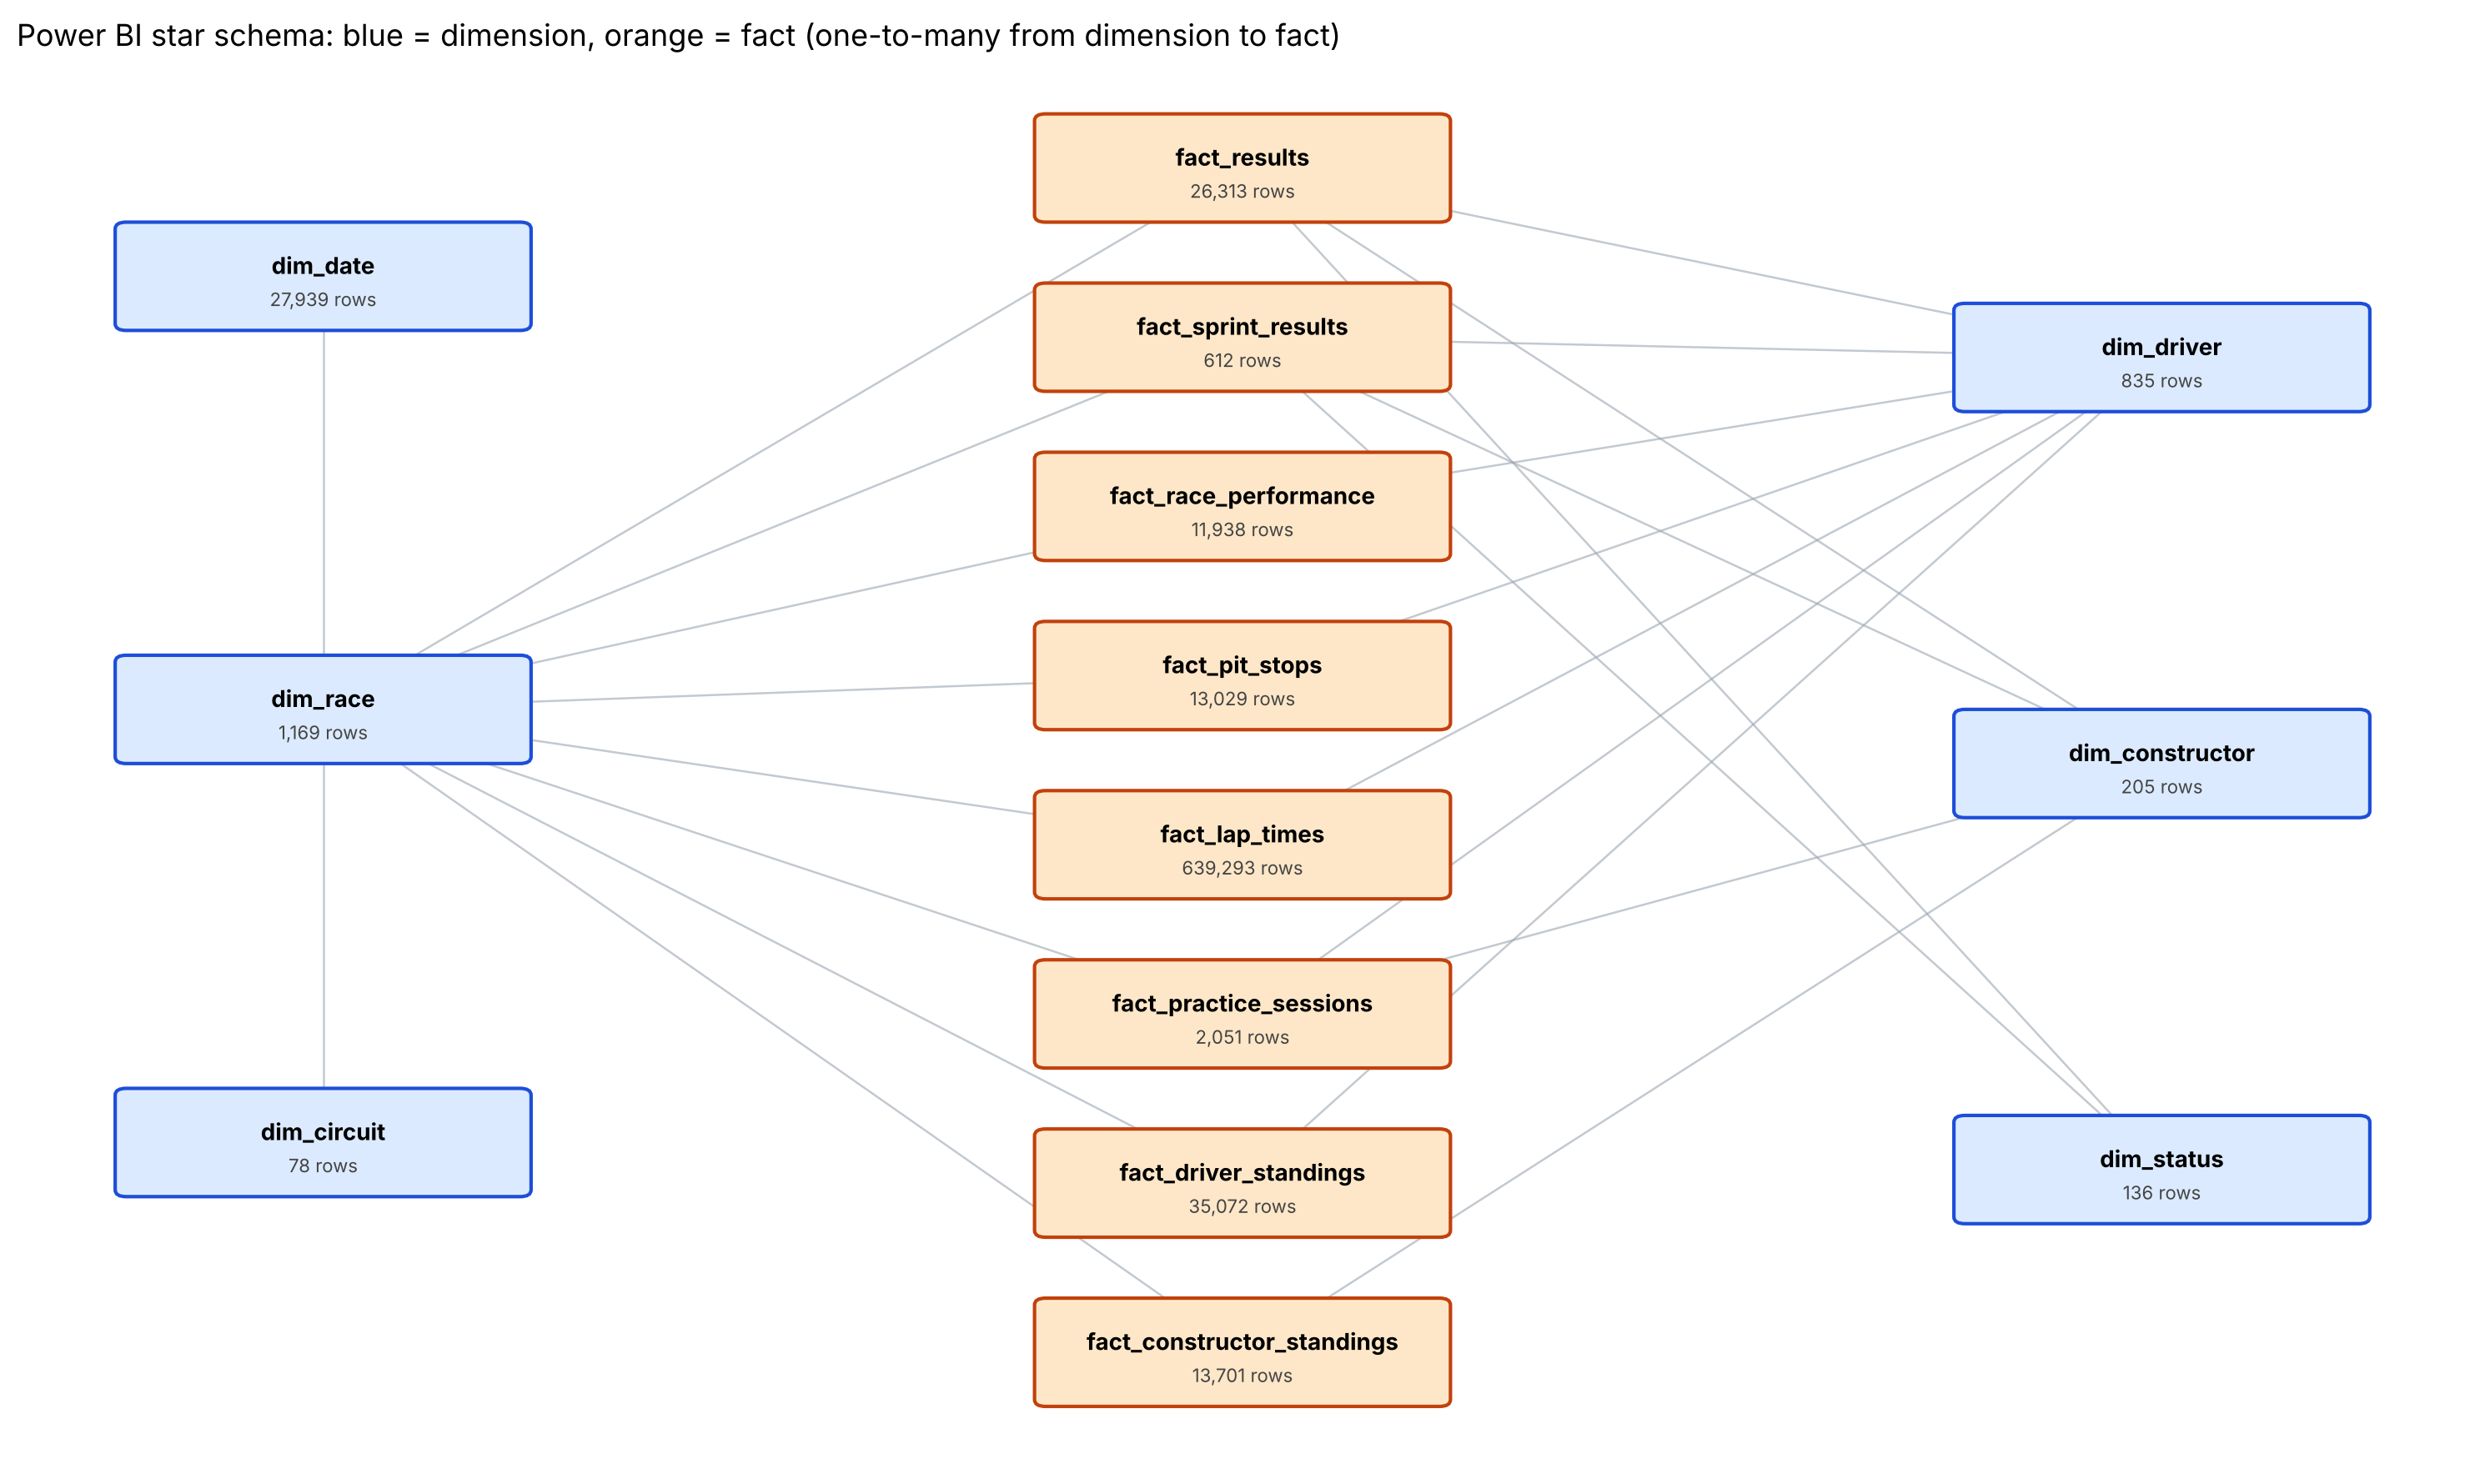

In [6]:
LAYOUT = {
    "dim_date": (0.08, 0.86), "dim_race": (0.08, 0.54), "dim_circuit": (0.08, 0.22),
    "dim_driver": (0.92, 0.80), "dim_constructor": (0.92, 0.50), "dim_status": (0.92, 0.20),
}
for index, name in enumerate(facts):
    LAYOUT[name] = (0.50, 0.94 - index * 0.125)

fig, ax = plt.subplots(figsize=(15, 9))
ax.set_xlim(-0.06, 1.06)
ax.set_ylim(-0.02, 1.02)
ax.axis("off")
for many, _, one, _ in RELATIONSHIPS:
    (x1, y1), (x2, y2) = LAYOUT[one], LAYOUT[many]
    ax.plot([x1, x2], [y1, y2], color="#9aa5b1", lw=0.9, alpha=0.6, zorder=1)
for name, (x, y) in LAYOUT.items():
    is_dimension = name.startswith("dim_")
    ax.add_patch(FancyBboxPatch((x - 0.09, y - 0.035), 0.18, 0.07, boxstyle="round,pad=0.005",
                                fc="#dbeafe" if is_dimension else "#fde7c8",
                                ec="#1d4ed8" if is_dimension else "#c2410c", lw=1.5, zorder=2))
    ax.text(x, y + 0.008, name, ha="center", va="center", fontsize=10, fontweight="bold", zorder=3)
    ax.text(x, y - 0.017, f"{len(warehouse[name]):,} rows", ha="center", va="center", fontsize=8, color="#444", zorder=3)
ax.set_title("Power BI star schema: blue = dimension, orange = fact (one-to-many from dimension to fact)", fontsize=13, loc="left")
plt.tight_layout()
plt.show()

## 5.5 Export

In [7]:
for fmt in ("parquet", "csv"):
    (PBI_DIR / fmt).mkdir(exist_ok=True)

for name, df in warehouse.items():
    df = df.reset_index(drop=True)
    df.to_parquet(PBI_DIR / "parquet" / f"{name}.parquet", index=False)
    df.to_csv(PBI_DIR / "csv" / f"{name}.csv", index=False, date_format="%Y-%m-%d")

pd.DataFrame(RELATIONSHIPS, columns=["many_table", "many_column", "one_table", "one_column"]).to_csv(
    PBI_DIR / "relationships.csv", index=False
)

dictionary = pd.DataFrame([
    {"table": name, "column": column, "dtype": str(df[column].dtype), "null_count": int(df[column].isna().sum())}
    for name, df in warehouse.items() for column in df.columns
])
dictionary.to_csv(PBI_DIR / "data_dictionary.csv", index=False)

export_summary = pd.DataFrame({
    "rows": {name: len(df) for name, df in warehouse.items()},
    "columns": {name: df.shape[1] for name, df in warehouse.items()},
    "parquet_mb": {name: round((PBI_DIR / "parquet" / f"{name}.parquet").stat().st_size / 1024**2, 2) for name in warehouse},
    "csv_mb": {name: round((PBI_DIR / "csv" / f"{name}.csv").stat().st_size / 1024**2, 2) for name in warehouse},
})
display(export_summary)
print(f"Exported {len(warehouse)} tables to {PBI_DIR.name}/")

,rows,columns,parquet_mb,csv_mb
dim_date,27939,10,0.40,1.46
dim_race,1169,16,0.04,0.14
dim_circuit,78,8,0.01,0.01
dim_driver,835,7,0.04,0.04
dim_constructor,205,4,0.01,0.01
dim_status,136,4,0.00,0.01
fact_results,26313,33,0.60,3.53
fact_sprint_results,612,16,0.02,0.04
fact_race_performance,11938,17,0.39,0.92
fact_pit_stops,13029,6,0.09,0.33


Exported 14 tables to f1_powerbi/


## 5.6 Power BI guide

The guide covers relationships, model settings, modelling pitfalls, the DAX measures and the dashboard layout. It is also saved as `Power_BI_Guide.md` next to the exported tables.

In [8]:
GUIDE = r'''
# Power BI Guide

## 1. Load the data

1. Run Phase 5 to export the star schema to `f1_powerbi/`.
2. In Power BI Desktop choose **Get data > Parquet** and load every file in `f1_powerbi/parquet`, or **Get data > Text/CSV** for `f1_powerbi/csv`.
3. Keep the table names exactly as the file names (for example `fact_results`).

## 2. Create the relationships

All relationships are one-to-many from the dimension to the fact, single direction, and active.

| From (one) | To (many) |
| --- | --- |
| `dim_date[date_key]` | `dim_race[date_key]` |
| `dim_circuit[circuit_id]` | `dim_race[circuit_id]` |
| `dim_race[race_id]` | `race_id` in every fact table |
| `dim_driver[driver_id]` | `driver_id` in `fact_results`, `fact_sprint_results`, `fact_race_performance`, `fact_pit_stops`, `fact_lap_times`, `fact_practice_sessions`, `fact_driver_standings` |
| `dim_constructor[constructor_id]` | `constructor_id` in `fact_results`, `fact_sprint_results`, `fact_practice_sessions`, `fact_constructor_standings` |
| `dim_status[status_id]` | `status_id` in `fact_results`, `fact_sprint_results` |

## 3. Model settings

- Mark `dim_date` as the date table using `date`.
- Sort `dim_date[month_name]` by `month` and `dim_date[day_name]` by `day_of_week`.
- Sort `dim_race[era]` by `dim_race[decade]`.
- Hide all key columns (`*_id`, `date_key`) and set numeric columns that should not be aggregated (`year`, `round`, `decade`) to **Don't summarize**.
- Format `*_ms` columns as whole numbers and `duration_s` with three decimals.

## 4. Avoid common modelling errors

| Risk | Guidance |
| --- | --- |
| Many-to-many between facts | Never relate two fact tables directly. `fact_race_performance` and `fact_results` meet only through `dim_race` and `dim_driver` |
| Duplicate `(race_id, driver_id)` pairs | They exist only in `fact_results` for 1950-1964 shared drives. Use `result_id` as the row key and do not relate on the pair |
| Summing standings | `fact_driver_standings` and `fact_constructor_standings` hold cumulative values after every round. Filter on `is_season_final` before summing |
| Blank means no coverage | Qualifying, lap, pit stop and sprint data start in different seasons. Use `dim_race[has_qualifying_data]`, `[has_lap_data]` and `[has_pit_data]` as page or visual filters |
| Averaging outliers | Keep `is_outlier_lap` and `is_outlier_stop` set to false in visuals that average times |
| Booleans in CSV | If you load CSV, confirm the `is_*` columns are typed as True/False |

## 5. DAX measures

Create a table named `_Measures` and add the following.

```dax
Races = DISTINCTCOUNT ( fact_results[race_id] )

Starts =
CALCULATE ( COUNTROWS ( fact_results ), fact_results[is_dns] = FALSE () )

Wins =
CALCULATE ( COUNTROWS ( fact_results ), fact_results[is_win] = TRUE () )

Podiums =
CALCULATE ( COUNTROWS ( fact_results ), fact_results[is_podium] = TRUE () )

Poles =
CALCULATE ( COUNTROWS ( fact_results ), fact_results[started_on_pole] = TRUE () )

Fastest Laps =
CALCULATE ( COUNTROWS ( fact_results ), fact_results[has_fastest_lap] = TRUE () )

Retirements =
CALCULATE ( COUNTROWS ( fact_results ), fact_results[is_dnf] = TRUE () )

Win Rate = DIVIDE ( [Wins], [Starts] )

Podium Rate = DIVIDE ( [Podiums], [Starts] )

Retirement Rate = DIVIDE ( [Retirements], [Starts] )

Finish Rate =
DIVIDE (
    CALCULATE ( COUNTROWS ( fact_results ), fact_results[is_finished] = TRUE () ),
    [Starts]
)

Pole Conversion =
DIVIDE (
    CALCULATE (
        COUNTROWS ( fact_results ),
        fact_results[started_on_pole] = TRUE (),
        fact_results[is_win] = TRUE ()
    ),
    [Poles]
)

Race Points = SUM ( fact_results[points] )

Sprint Points = SUM ( fact_sprint_results[points] )

Total Points = [Race Points] + [Sprint Points]

Avg Grid Position = AVERAGE ( fact_results[grid_position] )

Avg Finish Position = AVERAGE ( fact_results[finish_position] )

Avg Positions Gained = AVERAGE ( fact_results[positions_gained] )

Season Points =
CALCULATE (
    SUM ( fact_driver_standings[points] ),
    fact_driver_standings[is_season_final] = TRUE ()
)

Driver Titles =
CALCULATE (
    COUNTROWS ( fact_driver_standings ),
    fact_driver_standings[is_season_final] = TRUE (),
    fact_driver_standings[position] = 1
)

Constructor Titles =
CALCULATE (
    COUNTROWS ( fact_constructor_standings ),
    fact_constructor_standings[is_season_final] = TRUE (),
    fact_constructor_standings[position] = 1
)

Avg Pit Stop (s) =
CALCULATE (
    AVERAGE ( fact_pit_stops[duration_s] ),
    fact_pit_stops[is_outlier_stop] = FALSE ()
)

Avg Stops per Driver =
AVERAGE ( fact_race_performance[pit_stops] )

Best Lap (s) =
DIVIDE (
    CALCULATE ( MIN ( fact_lap_times[lap_time_ms] ), fact_lap_times[is_outlier_lap] = FALSE () ),
    1000
)
```

`Season Points`, `Driver Titles` and `Constructor Titles` are meaningful at season or driver level. Use them with `dim_race[year]` or `dim_driver[driver_name]` in the filter context.

## 6. Dashboard design

| Page | Purpose | Visuals |
| --- | --- | --- |
| Overview | Entry point | Cards for `Races`, `Wins`, `Podiums`, `Poles`; line chart of `Finish Rate` by `year`; table of season champions using `Driver Titles` |
| Drivers | Compare drivers | Slicers for `dim_race[era]` and `dim_driver[nationality]`; bar chart of `Wins` by driver; scatter of `Win Rate` against `Starts`; matrix of `Podiums` by year |
| Constructors | Team performance | Stacked column of `Wins` by `decade` and constructor; line chart of `Season Points`; `Retirement Rate` by constructor |
| Circuits | Track insights | Map of `dim_circuit` with `Retirement Rate` as bubble size; bar chart of `Pole Conversion` by circuit; `Avg Positions Gained` table |
| Qualifying and grid | Starting position impact | Column chart of `Win Rate` by `grid_position`; heat map of `Podium Rate` by grid position and era |
| Race strategy | Pit stops and pace | Line chart of `Avg Pit Stop (s)` by year; `Avg Stops per Driver` by year; `Best Lap (s)` by circuit. Filter on `dim_race[has_pit_data]` |

Use a consistent theme: neutral background, one accent colour (`#E10600`), and the same era ordering on every page.
'''

(PBI_DIR / "Power_BI_Guide.md").write_text(GUIDE, encoding="utf-8")
display(Markdown(GUIDE))


# Power BI Guide

## 1. Load the data

1. Run Phase 5 to export the star schema to `f1_powerbi/`.
2. In Power BI Desktop choose **Get data > Parquet** and load every file in `f1_powerbi/parquet`, or **Get data > Text/CSV** for `f1_powerbi/csv`.
3. Keep the table names exactly as the file names (for example `fact_results`).

## 2. Create the relationships

All relationships are one-to-many from the dimension to the fact, single direction, and active.

| From (one) | To (many) |
| --- | --- |
| `dim_date[date_key]` | `dim_race[date_key]` |
| `dim_circuit[circuit_id]` | `dim_race[circuit_id]` |
| `dim_race[race_id]` | `race_id` in every fact table |
| `dim_driver[driver_id]` | `driver_id` in `fact_results`, `fact_sprint_results`, `fact_race_performance`, `fact_pit_stops`, `fact_lap_times`, `fact_practice_sessions`, `fact_driver_standings` |
| `dim_constructor[constructor_id]` | `constructor_id` in `fact_results`, `fact_sprint_results`, `fact_practice_sessions`, `fact_constructor_standings` |
| `dim_status[status_id]` | `status_id` in `fact_results`, `fact_sprint_results` |

## 3. Model settings

- Mark `dim_date` as the date table using `date`.
- Sort `dim_date[month_name]` by `month` and `dim_date[day_name]` by `day_of_week`.
- Sort `dim_race[era]` by `dim_race[decade]`.
- Hide all key columns (`*_id`, `date_key`) and set numeric columns that should not be aggregated (`year`, `round`, `decade`) to **Don't summarize**.
- Format `*_ms` columns as whole numbers and `duration_s` with three decimals.

## 4. Avoid common modelling errors

| Risk | Guidance |
| --- | --- |
| Many-to-many between facts | Never relate two fact tables directly. `fact_race_performance` and `fact_results` meet only through `dim_race` and `dim_driver` |
| Duplicate `(race_id, driver_id)` pairs | They exist only in `fact_results` for 1950-1964 shared drives. Use `result_id` as the row key and do not relate on the pair |
| Summing standings | `fact_driver_standings` and `fact_constructor_standings` hold cumulative values after every round. Filter on `is_season_final` before summing |
| Blank means no coverage | Qualifying, lap, pit stop and sprint data start in different seasons. Use `dim_race[has_qualifying_data]`, `[has_lap_data]` and `[has_pit_data]` as page or visual filters |
| Averaging outliers | Keep `is_outlier_lap` and `is_outlier_stop` set to false in visuals that average times |
| Booleans in CSV | If you load CSV, confirm the `is_*` columns are typed as True/False |

## 5. DAX measures

Create a table named `_Measures` and add the following.

```dax
Races = DISTINCTCOUNT ( fact_results[race_id] )

Starts =
CALCULATE ( COUNTROWS ( fact_results ), fact_results[is_dns] = FALSE () )

Wins =
CALCULATE ( COUNTROWS ( fact_results ), fact_results[is_win] = TRUE () )

Podiums =
CALCULATE ( COUNTROWS ( fact_results ), fact_results[is_podium] = TRUE () )

Poles =
CALCULATE ( COUNTROWS ( fact_results ), fact_results[started_on_pole] = TRUE () )

Fastest Laps =
CALCULATE ( COUNTROWS ( fact_results ), fact_results[has_fastest_lap] = TRUE () )

Retirements =
CALCULATE ( COUNTROWS ( fact_results ), fact_results[is_dnf] = TRUE () )

Win Rate = DIVIDE ( [Wins], [Starts] )

Podium Rate = DIVIDE ( [Podiums], [Starts] )

Retirement Rate = DIVIDE ( [Retirements], [Starts] )

Finish Rate =
DIVIDE (
    CALCULATE ( COUNTROWS ( fact_results ), fact_results[is_finished] = TRUE () ),
    [Starts]
)

Pole Conversion =
DIVIDE (
    CALCULATE (
        COUNTROWS ( fact_results ),
        fact_results[started_on_pole] = TRUE (),
        fact_results[is_win] = TRUE ()
    ),
    [Poles]
)

Race Points = SUM ( fact_results[points] )

Sprint Points = SUM ( fact_sprint_results[points] )

Total Points = [Race Points] + [Sprint Points]

Avg Grid Position = AVERAGE ( fact_results[grid_position] )

Avg Finish Position = AVERAGE ( fact_results[finish_position] )

Avg Positions Gained = AVERAGE ( fact_results[positions_gained] )

Season Points =
CALCULATE (
    SUM ( fact_driver_standings[points] ),
    fact_driver_standings[is_season_final] = TRUE ()
)

Driver Titles =
CALCULATE (
    COUNTROWS ( fact_driver_standings ),
    fact_driver_standings[is_season_final] = TRUE (),
    fact_driver_standings[position] = 1
)

Constructor Titles =
CALCULATE (
    COUNTROWS ( fact_constructor_standings ),
    fact_constructor_standings[is_season_final] = TRUE (),
    fact_constructor_standings[position] = 1
)

Avg Pit Stop (s) =
CALCULATE (
    AVERAGE ( fact_pit_stops[duration_s] ),
    fact_pit_stops[is_outlier_stop] = FALSE ()
)

Avg Stops per Driver =
AVERAGE ( fact_race_performance[pit_stops] )

Best Lap (s) =
DIVIDE (
    CALCULATE ( MIN ( fact_lap_times[lap_time_ms] ), fact_lap_times[is_outlier_lap] = FALSE () ),
    1000
)
```

`Season Points`, `Driver Titles` and `Constructor Titles` are meaningful at season or driver level. Use them with `dim_race[year]` or `dim_driver[driver_name]` in the filter context.

## 6. Dashboard design

| Page | Purpose | Visuals |
| --- | --- | --- |
| Overview | Entry point | Cards for `Races`, `Wins`, `Podiums`, `Poles`; line chart of `Finish Rate` by `year`; table of season champions using `Driver Titles` |
| Drivers | Compare drivers | Slicers for `dim_race[era]` and `dim_driver[nationality]`; bar chart of `Wins` by driver; scatter of `Win Rate` against `Starts`; matrix of `Podiums` by year |
| Constructors | Team performance | Stacked column of `Wins` by `decade` and constructor; line chart of `Season Points`; `Retirement Rate` by constructor |
| Circuits | Track insights | Map of `dim_circuit` with `Retirement Rate` as bubble size; bar chart of `Pole Conversion` by circuit; `Avg Positions Gained` table |
| Qualifying and grid | Starting position impact | Column chart of `Win Rate` by `grid_position`; heat map of `Podium Rate` by grid position and era |
| Race strategy | Pit stops and pace | Line chart of `Avg Pit Stop (s)` by year; `Avg Stops per Driver` by year; `Best Lap (s)` by circuit. Filter on `dim_race[has_pit_data]` |

Use a consistent theme: neutral background, one accent colour (`#E10600`), and the same era ordering on every page.


## 5.7 Package the deliverables

In [9]:
shutil.make_archive(str(BASE / "f1_powerbi"), "zip", PBI_DIR)
print("Created", (BASE / "f1_powerbi.zip").name)
if IN_COLAB:
    files.download(str(BASE / "f1_powerbi.zip"))

Created f1_powerbi.zip


## Next Steps

1. Open Power BI Desktop and load the tables from `f1_powerbi/parquet`.
2. Create the relationships listed in `relationships.csv` (single direction, one-to-many).
3. Add the DAX measures from the guide to a `_Measures` table.
4. Build the six report pages described in the guide.